<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

Setup complete


---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [3]:
def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
df["label_text"].value_counts()

Loaded from Hugging Face
Shape: (11314, 3), columns: ['text', 'label', 'label_text']


label_text
rec.sport.hockey            600
soc.religion.christian      599
rec.motorcycles             598
rec.sport.baseball          597
sci.crypt                   595
rec.autos                   594
sci.med                     594
comp.windows.x              593
sci.space                   593
comp.os.ms-windows.misc     591
sci.electronics             591
comp.sys.ibm.pc.hardware    590
misc.forsale                585
comp.graphics               584
comp.sys.mac.hardware       578
talk.politics.mideast       564
talk.politics.guns          546
alt.atheism                 480
talk.politics.misc          465
talk.religion.misc          377
Name: count, dtype: int64

In [4]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

Label: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [ ]:
print(sorted(df["label_text"].unique()))

my_categories = ["rec.sport.baseball", "rec.sport.hockey", "sci.space"]

assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
df_filtered["label_text"].value_counts()

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Selected categories: ['rec.sport.baseball', 'rec.sport.hockey', 'sci.space']
Filtered dataset: 1790 documents


label_text
rec.sport.hockey      600
rec.sport.baseball    597
sci.space             593
Name: count, dtype: int64

### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)

<!-- ANSWER lab3.1-A2 -->
**Your answer:**

I chose baseball and hockey because both are team sports, so comparing them should reveal shared vocabulary as well as sport-specific terms. I added space as a contrasting science topic; I expect words such as *run* and *hit* in baseball, *goal* and *period* in hockey, and *NASA*, *launch*, and *orbit* in space discussions. This mix lets me compare two related groups with one clearly different group and distinguish topic words from general discussion words.
<!-- END ANSWER -->

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [6]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

hello check this email me at price


### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [7]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    """Basic cleaning + stop word removal + lemmatization + minimum length 3. Returns a string."""
    tokens = word_tokenize(preprocess_basic(text))
    tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words]
    tokens = [token for token in tokens if len(token) >= 3]
    return " ".join(tokens)

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [8]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

article tom baker understanding expected error basically known bug warning system software thing checked right value yet set till launch suchlike rather fix code possibly introduce new bug tell crew see warning liftoff ignore


---
# Part C – Visualization

## C.1 Most frequent words per category

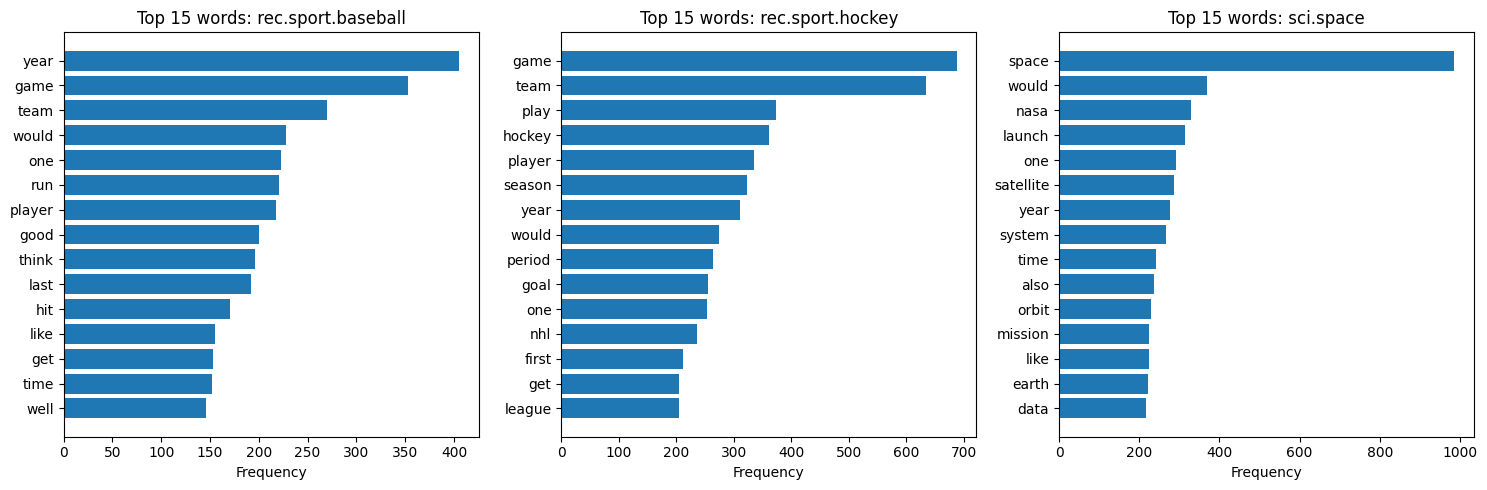

In [9]:
def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

<!-- ANSWER lab3.1-C1 -->
**Your answer:**

In this run, baseball-specific words among the frequent terms include *run* and *hit*; hockey has *hockey*, *goal*, *period*, and *NHL*; and space has *NASA*, *launch*, *satellite*, and *orbit*. All three lists also contain general terms such as *year*, *would*, and *one*. The word *would* remains because it is not in NLTK's default English stop-word list, and this preprocessing step removes only words on that list. The top words identify broad subjects, but shared and generic words mean they do not describe every document or make a precise topic classifier by themselves.
<!-- END ANSWER -->

## C.2 Word clouds

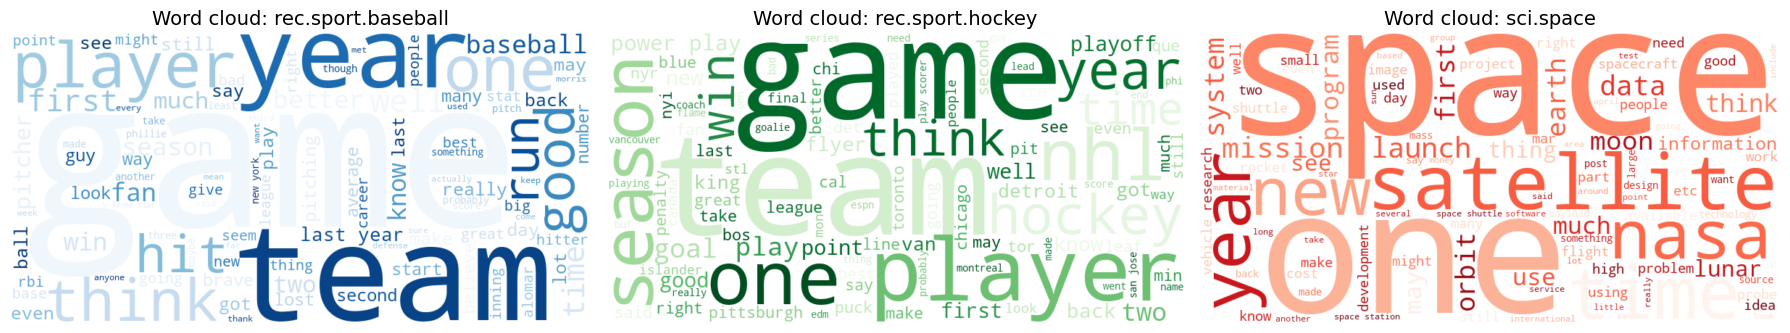

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

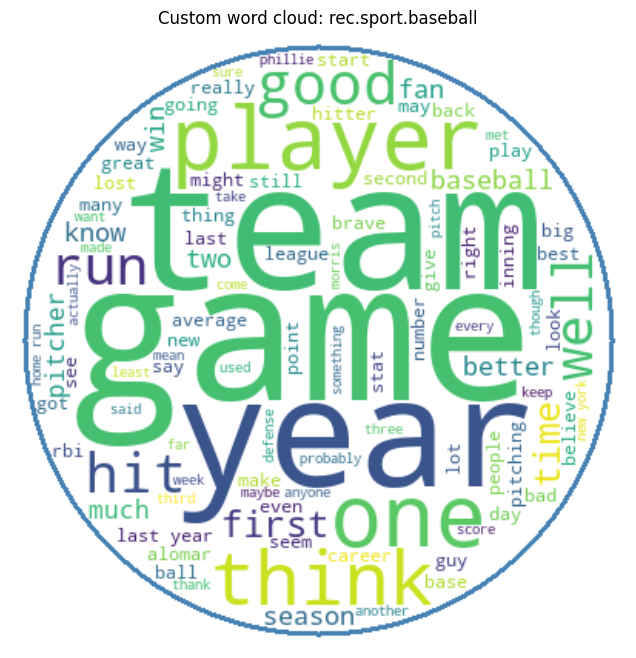

In [11]:
from PIL import Image

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()
# To use your own image instead:  mask = np.array(Image.open("my_shape.png").convert("L"))

selected_category = my_categories[0]
texts = df_filtered.loc[df_filtered["label_text"] == selected_category, "text_clean"]
text_combined = " ".join(texts.astype(str))
wordcloud_masked = WordCloud(
    width=800, height=800, background_color="white", mask=mask,
    contour_width=2, contour_color="steelblue", colormap="viridis", max_words=100,
).generate(text_combined)

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

---
# Part D – Bag of Words

In [12]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

Vocabulary: ['deep' 'great' 'is' 'learning' 'love' 'machine' 'too']


,deep,great,is,learning,love,machine,too
0,0,0,0,1,1,1,0
1,0,1,1,1,0,1,0
2,1,0,0,1,1,0,1


### Exercise D.1 – Bag of Words of your corpus

In [13]:
# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = CountVectorizer(max_features=1000, min_df=5, max_df=0.95)
bow_matrix_full = bow_vectorizer_full.fit_transform(df_filtered["text_clean"])

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1790, 1000)
Sparsity: 97.0% of zeros
First 20 words: ['abc' 'ability' 'able' 'access' 'according' 'acquired' 'activity'
 'actually' 'adam' 'add' 'address' 'adirondack' 'advantage' 'advertising'
 'aerospace' 'age' 'agency' 'ago' 'agree' 'ahead']


### Exercise D.2 – Document similarity

In [14]:
# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
# 2. Find the most similar pair of distinct documents (ignore the diagonal)
similarity_matrix = cosine_similarity(bow_matrix_full)
similarity_for_search = similarity_matrix.copy()
np.fill_diagonal(similarity_for_search, -np.inf)
most_similar_idx = tuple(int(i) for i in np.unravel_index(np.argmax(similarity_for_search), similarity_for_search.shape))
most_similar_score = float(similarity_matrix[most_similar_idx])

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

Similarity matrix shape: (1790, 1790)
Most similar documents: (479, 602), score = 1.000

Document 1 (sci.space):

  Thanks for these surreal moments....
                                               Srinivas

Document 2 (sci.space):
Thanks for the Update.


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**Your answer:**

In this run, the pair reported by `argmax` is documents 479 and 602, both from *sci.space*. They are short thank-you replies rather than substantive articles. After applying the selected 1,000-word vocabulary, both retain only the feature *thanks*, giving a cosine similarity of 1.0. At three decimal places, five unordered pairs display as 1.000, so `argmax` shows only one of the top pairs. This score measures lexical overlap, not meaning: BoW ignores word order and context, and short messages can receive misleadingly high similarity.
<!-- END ANSWER -->

---
# Part E – TF-IDF

In [15]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

,deep,great,is,learning,love,machine,too
0,0.000,0.000,0.000,0.481,0.620,0.620,0.000
1,0.000,0.584,0.584,0.345,0.000,0.445,0.000
2,0.584,0.000,0.000,0.345,0.445,0.000,0.584


In [16]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

Scores of the word 'learning' (present in every document):
  BoW:    [1, 1, 1]
  TF-IDF: [0.481, 0.345, 0.345] -> lower weight for a word shared by all documents


### Exercise E.1 – TF-IDF of your corpus and top words per category

In [17]:
tfidf_vectorizer_full = TfidfVectorizer(max_features=1000, min_df=5, max_df=0.95)
tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(df_filtered["text_clean"])
print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

def get_top_tfidf_words(category, n=10):
    """Words with the highest mean TF-IDF over the documents of a category."""
    category_mask = df_filtered["label_text"].eq(category).to_numpy()
    if not category_mask.any():
        raise ValueError(f"Unknown or empty category: {category!r}")

    category_scores = np.asarray(tfidf_matrix_full[category_mask].mean(axis=0)).ravel()
    top_indices = np.argsort(category_scores)[::-1][:n]
    feature_names = tfidf_vectorizer_full.get_feature_names_out()
    return [(feature_names[i], float(category_scores[i])) for i in top_indices]

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

TF-IDF matrix shape: (1790, 1000)

Top TF-IDF words for 'rec.sport.baseball':
[('year', 0.04466459977404479), ('game', 0.041912024960877474), ('run', 0.03413233619110016), ('team', 0.03296873388713109), ('baseball', 0.029744419498726887), ('player', 0.028666257878628816), ('think', 0.027812394309964718), ('hit', 0.0273080134403953), ('one', 0.02680326269556679), ('last', 0.02468880661475159)]

Top TF-IDF words for 'rec.sport.hockey':
[('game', 0.06111771462502493), ('team', 0.0510173961211267), ('hockey', 0.04064725592936728), ('player', 0.03618226819825188), ('play', 0.030967106824151085), ('would', 0.030008811075119234), ('year', 0.027017608595625436), ('nhl', 0.026680005952164094), ('season', 0.02643086072038231), ('playoff', 0.02593065467769274)]

Top TF-IDF words for 'sci.space':
[('space', 0.06973859307759163), ('would', 0.04003192569509001), ('like', 0.028202106976428366), ('one', 0.028174959546512064), ('nasa', 0.02655238082462361), ('launch', 0.02484514661928238), ('orbit', 0.

### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

<!-- ANSWER lab3.1-E2 -->
**Your answer:**

Comparing each category's TF-IDF top 10 with its count top 15, the words found only in TF-IDF are *baseball* for baseball, *playoff* for hockey, and *get*, *moon*, and *thing* for space. The words found only in the count lists are *would*, *good*, *like*, *get*, *time*, and *well* for baseball; *period*, *goal*, *one*, *first*, *get*, and *league* for hockey; and *satellite*, *year*, *system*, *time*, *also*, *mission*, *earth*, and *data* for space. TF-IDF is only slightly more useful for identifying topics here: it surfaces terms such as *baseball*, *playoff*, and *moon*, but its space list still includes generic words such as *would*, *like*, *one*, *get*, and *thing*. Counts also retain informative topic terms such as *period*, *goal*, *satellite*, and *mission*. The distinction between the representations is limited in this corpus.
<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [18]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

Bigrams:  [('I', 'love'), ('love', 'natural'), ('natural', 'language'), ('language', 'processing'), ('processing', 'and'), ('and', 'machine'), ('machine', 'learning')]
Trigrams: [('I', 'love', 'natural'), ('love', 'natural', 'language'), ('natural', 'language', 'processing'), ('language', 'processing', 'and'), ('processing', 'and', 'machine'), ('and', 'machine', 'learning')]
Bigram features: ['is great' 'learning is' 'love machine' 'machine learning']


### Exercise F.1 – Most frequent bigrams per category

In [19]:
def top_bigrams(texts, n=15):
    """(bigram, count) list of the n most frequent bigrams in the texts."""
    vectorizer = CountVectorizer(ngram_range=(2, 2), min_df=3)
    bigram_matrix = vectorizer.fit_transform(texts)
    bigram_counts = np.asarray(bigram_matrix.sum(axis=0)).ravel()
    top_indices = np.argsort(bigram_counts)[::-1][:n]
    bigrams = vectorizer.get_feature_names_out()
    return [(bigrams[i], int(bigram_counts[i])) for i in top_indices]

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'rec.sport.baseball':
  last year: 98
  new york: 49
  home run: 44
  red sox: 35
  major league: 25
  pitching staff: 22
  los angeles: 21
  world series: 21
  san francisco: 20
  san diego: 19
  white sox: 17
  run scored: 17
  blue jay: 17
  year old: 17
  much better: 16

Top bigrams for 'rec.sport.hockey':
  power play: 145
  play scorer: 63
  san jose: 62
  third period: 58
  new jersey: 56
  second period: 56
  los angeles: 55
  first period: 53
  hockey league: 52
  tampa bay: 50
  stanley cup: 49
  new york: 45
  last year: 42
  brind amour: 42
  maple leaf: 40

Top bigrams for 'sci.space':


  space station: 69
  space shuttle: 66
  sci space: 58
  anonymous ftp: 38
  commercial space: 32
  remote sensing: 32
  gamma ray: 28
  launch vehicle: 27
  national space: 26
  sci astro: 25
  air force: 24
  nasa ames: 24
  nasa gov: 24
  space technology: 23
  pub space: 21


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [20]:
class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}   # {word1: Counter({word2: count, ...})}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts (strings)."""
        self.bigram_counts = {}
        self.unigram_counts = Counter()
        for text in texts:
            tokens = str(text).lower().split()
            self.unigram_counts.update(tokens)
            for word1, word2 in zip(tokens, tokens[1:]):
                self.bigram_counts.setdefault(word1, Counter())[word2] += 1
        return self

    def predict_next(self, word, top_n=5):
        """Return the top_n (next_word, probability) pairs for a word."""
        word = str(word).lower()
        total = self.unigram_counts[word]
        if total == 0 or top_n <= 0:
            return []
        predictions = [
            (next_word, count / total)
            for next_word, count in self.bigram_counts.get(word, {}).items()
        ]
        return sorted(predictions, key=lambda item: (-item[1], item[0]))[:top_n]

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"]);

[('cat', 0.5), ('fish', 0.25), ('mat', 0.25)]


In [21]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = ["baseball", "hockey", "game", "space", "nasa"]

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")


'baseball' ->
  game: 0.064
  fan: 0.041
  fanatic: 0.035
  player: 0.035
  team: 0.029

'hockey' ->
  league: 0.142
  player: 0.044
  team: 0.044
  championship: 0.025
  game: 0.025

'game' ->
  played: 0.025
  season: 0.015
  game: 0.013
  last: 0.012
  point: 0.012

'space' ->
  station: 0.070
  shuttle: 0.067
  technology: 0.023
  program: 0.020
  news: 0.019

'nasa' ->
  ames: 0.073
  gov: 0.073
  center: 0.037
  budget: 0.021
  jsc: 0.018


### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**Your answer:**

Two sensible predictions in this run are *space → station* and *baseball → game*: both are common, topic-related continuations. Two weaker predictions are *game → game* and *nasa → gov*. The latter may come from a domain such as `nasa.gov`: the basic cleaning removes URLs with an `http(s)` or `www` prefix, but a bare domain can be split into ordinary tokens. A bigram model sees only the immediately previous word, so it cannot distinguish senses or use longer context; it also gives unreliable estimates for rare words and treats each text boundary separately. It could be improved with trigrams or a longer context window, smoothing and back-off for rare pairs, and a model using word embeddings or a neural language model.
<!-- END ANSWER -->

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

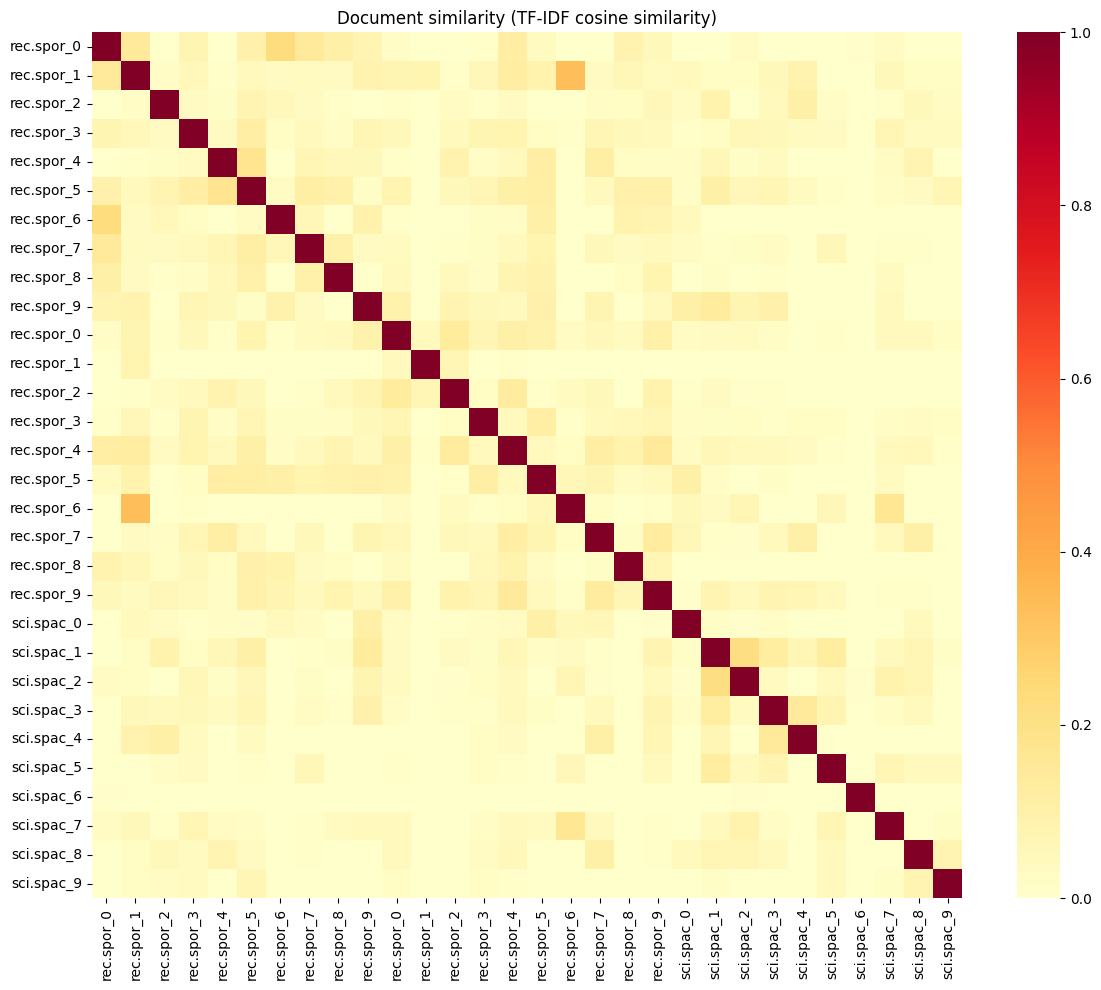

In [22]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

In [23]:
sampled_labels = df_sampled["label_text"].to_numpy()
upper_triangle = np.triu(np.ones_like(similarity_sampled, dtype=bool), k=1)

print("Documents sampled per category:")
for category in my_categories:
    print(f"  {category}: {(sampled_labels == category).sum()}")

print("\nWithin-category mean cosine similarity:")
for category in my_categories:
    in_category = sampled_labels == category
    pair_mask = upper_triangle & in_category[:, None] & in_category[None, :]
    print(f"  {category}: {similarity_sampled[pair_mask].mean():.3f} ({pair_mask.sum()} pairs)")

print("\nBetween-category mean cosine similarity:")
for i, category_a in enumerate(my_categories):
    for category_b in my_categories[i + 1:]:
        pair_mask = (sampled_labels[:, None] == category_a) & (sampled_labels[None, :] == category_b)
        print(f"  {category_a} / {category_b}: {similarity_sampled[pair_mask].mean():.3f} ({pair_mask.sum()} pairs)")

cross_category_pairs = upper_triangle & (sampled_labels[:, None] != sampled_labels[None, :])
i, j = np.unravel_index(np.argmax(np.where(cross_category_pairs, similarity_sampled, -np.inf)), similarity_sampled.shape)
print(f"\nHighest cross-category pair: rows {i + 1} and {j + 1}, {sampled_labels[i]} / {sampled_labels[j]}, cosine={similarity_sampled[i, j]:.3f}")
for row in (i, j):
    excerpt = " ".join(str(df_sampled.iloc[row]["text_clean"]).split())[:220]
    print(f"  Row {row + 1}: {excerpt}...")


Documents sampled per category:
  rec.sport.baseball: 10
  rec.sport.hockey: 10
  sci.space: 10

Within-category mean cosine similarity:
  rec.sport.baseball: 0.057 (45 pairs)
  rec.sport.hockey: 0.051 (45 pairs)
  sci.space: 0.034 (45 pairs)

Between-category mean cosine similarity:
  rec.sport.baseball / rec.sport.hockey: 0.044 (100 pairs)
  rec.sport.baseball / sci.space: 0.025 (100 pairs)
  rec.sport.hockey / sci.space: 0.021 (100 pairs)

Highest cross-category pair: rows 2 and 17, rec.sport.baseball / rec.sport.hockey, cosine=0.337
  Row 2: stuff upated inning score deleted exact time see message even result game necessary thanks hernandez post daily standing result every day supposed take compliment put wondering meant entirely compliment service entire ba...
  Row 17: sorry everyone wasting space matt day posted mailing list playoff stats lost address please put list thanks...


<!-- ANSWER lab3.1-G1 -->
**Your answer:**

Yes. Ignoring the dark diagonal of self-similarity, the heatmap shows somewhat brighter within-category blocks, but the separation is modest. The mean within-category similarities exceed the corresponding between-category means for all three categories: baseball is 0.057 and hockey is 0.051, compared with 0.044 between them; space is 0.034, compared with 0.025 for baseball–space and 0.021 for hockey–space. The baseball and hockey blocks are especially weakly separated. Baseball–hockey is the most similar pair of categories (0.044), and hockey–space is the least similar (0.021).

The highest cross-category pair is sample rows 2 and 17 (*rec.sport.baseball* and *rec.sport.hockey*), with similarity 0.337. The shared terms *list* and *mailing* contribute 0.247 of that score: both messages discuss a mailing list. The high similarity is therefore mainly driven by mailing-list wording, rather than shared sports or statistics vocabulary.

The cell above computes the block means and identifies this cross-category pair. These results use 10 sampled documents per category.
<!-- END ANSWER -->

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.